### Quo vadis, Quax? – Lösung Schritt für Schritt

*36. Bundeswettbewerb Informatik (2017/2018), 2. Runde, Aufgabe 3*

In einer abgelegenen und unwegsamen Gegend will Quax die Fähigkeiten seines neuen Quadcopters ausprobieren. Da wird aus dem Spiel
Ernst: Ein Tornado mit anschließender Überschwemmung vernichtet seine Essenvorräte, so dass er seinen Urlaub abbrechen und sofort die
lange Wanderung zurück zur einzigen Stadt der Provinz antreten muss. Außerdem hat sich die Landschaft vollkommen verändert – es haben
sich Flüsse und Seen gebildet, wo früher keine waren. Es ist nicht klar, ob es überhaupt noch einen gangbaren Weg zurück zur Stadt
gibt und, falls ja, wo sich ein solcher Weg zwischen den Gewässern durchschlängelt.

Quax möchte die Landschaft mit dem Quadcopter erkunden, bevor er loslegt, um lange Umwege zu vermeiden, die er sich nicht leisten
kann. Der Quadcopter kann in einer frei wählbaren Flughöhe einen beliebigen Punkt der Landschaft anfliegen. Allerdings ist auch er
beschädigt: Die Speicherkarte ist hin, und es funktioniert nur ein einziger Sensor. Dieser erfasst ein quadratisches, nach Norden
ausgerichtetes Gebiet unter dem Quadcopter, dessen Seitenlänge proportional zur Flughöhe ist. Der Sensor kann für dieses Testgebiet
entscheiden, ob es ganz von Wasser bedeckt ist („Wasser“), ganz aus trockenem Land besteht („Land“) oder sowohl Wasser als auch Land
enthält („Gemischt“).

Quax kann wiederholt den Quadcopter für eine bestimmte Kombination aus Flughöhe und Zielpunkt programmieren, ihn entsenden und bei
seiner Rückkehr das Ergebnis („Wasser“, „Land“ oder „Gemischt“) in Empfang nehmen. Liefert der Quadcopter auch für ein
kleinstmögliches Testgebiet mit Seitenlänge 20 m immer noch das Ergebnis „Gemischt“, geht Quax davon aus, dass er dieses Testgebiet
überqueren kann – zur Not schwimmt er ein paar Meter mit dem Gepäck. Das folgende Pixelbild *(im Aufgabenblatt)* zeigt eine
Beispiel-Landschaft. Jedes Pixel repräsentiert einen quadratischen Bereich der Landschaft mit Seitenlänge 10 m. Das grüne Pixel zeigt
die Position der Stadt. Vom oberen roten Startpunkt kann Quax die Stadt erreichen, vom unteren aber nicht.

#### Aufgabe

(a) Schreibe ein Programmmodul, das aus den Ergebnissen durchgeführter Flüge bestimmt, ob es für Quax einen gangbaren Weg zurück zur
Stadt gibt, ob es definitiv keinen solchen Weg gibt oder ob mehr Flüge nötig sind, um eine Entscheidung herbeizuführen.

(b) Beschreibe eine Strategie für das Entsenden des Quadcopters, die mit möglichst wenig Flügen einen Weg zur Stadt findet, falls es
einen gibt.

(c) Schreibe ein Programm, das eine Landschaft einliest, in welcher die Stadt sowie mehrere mögliche Standorte von Quax markiert sind.
Ein Pixel repräsentiert ein Quadrat der Seitenlänge 10 m. Dann soll das Programm die anhand der Strategie aus (b) festgelegten
Entsendungen – für jeden Standort des Quadcopters einzeln – simulieren. Ausgeben soll es je eine Darstellung der Landschaft, in der
die Testgebiete mit ihren jeweiligen Ergebnissen geeignet eingetragen sind. Falls es einen gangbaren Weg zur Stadt gibt, soll dieser
in der Darstellung erkennbar sein.

Wende dein Programm mindestens auf die auf der BWINF-Website gegebenen Beispiele an und dokumentiere die Ergebnisse. Gehe davon aus,
dass sich außerhalb der eingelesenen Landschaft nur Wasser befindet.

(d) Gibt es Verteilungen von Flüssen und Seen, bei denen deine Strategie aus (b) zu sehr vielen Flügen führt? Falls nein, erkläre
warum nicht. Falls ja, gib ein Beispiel dafür an und erkläre, worin das Problem besteht.

#### Beispieldaten

Im Ordner `beispieldaten` liegen `quax1.png`, `quax2.png` und `quax3.png` (dieselben Bilder gibt es auf der BWINF-Website auch als
große PPM-Dateien). Eine Formatbeschreibung gibt es nicht; aus den Bildern liest man ab: **Weiß ist Wasser, Schwarz ist Land**, rote
Pixel sind Standorte von Quax, das eine grüne Pixel ist die Stadt. In `quax2.png` gibt es außerdem einige dunkelgraue Pixel am Rand
der Flüsse; wir zählen sie zum Land.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Quadtree (Quaternärbaum):** Ein Quadrat wird in vier gleich große Viertel geteilt, jedes Viertel wieder in vier und so weiter.
  Das passt genau zum Sensor: Sagt er bei einem großen Quadrat „Land“ oder „Wasser“, wissen wir mit einem einzigen Flug über alle
  Planquadrate darin Bescheid. Nur bei „Gemischt“ müssen wir die Viertel ansehen.
- **Breitensuche** auf einem Gitter: Mit vollem Wissen über die Karte findet sie heraus, ob es einen Weg gibt. Damit bauen wir einen
  **Schiedsrichter**, der unsere Ergebnisse prüft (Quax kennt die Karte natürlich nicht).
- **Dijkstra-Algorithmus und A\*:** Dijkstra findet den billigsten Weg in einem Graphen mit Kosten an den Kanten. A* ist Dijkstra mit
  einer Schätzung des Restwegs (hier der Manhattan-Abstand zum Ziel); dadurch sucht er zuerst in Richtung Ziel.
- **Optimistisch planen:** Was wir noch nicht kennen, nehmen wir als begehbar an. Findet die Suche selbst dann keinen Weg, gibt es
  sicher keinen. Findet sie einen, sehen wir genau dort nach. So arbeiten auch Roboter in unbekanntem Gelände.

**Nützliche Funktionen und Bibliotheken**
- `PIL.Image.open(dateiname).convert('RGB')` öffnet ein PNG-Bild (Bibliothek Pillow, in JupyterLite vorhanden).
- `numpy`: `np.array(bild)` macht aus dem Bild eine Tabelle mit `hoehe × breite × 3` Farbwerten. Der Ausschnitt `land[y0:y1, x0:x1]`
  ist ein Rechteck der Tabelle, `.sum()` zählt darin die `True`-Werte. Ragt der Ausschnitt über den Rand hinaus, schneidet numpy ihn
  einfach ab. Das ist unser simulierter Sensor.
- `heapq.heappush` und `heapq.heappop` für die Warteschlange von Dijkstra und A*: `heappop` gibt immer das kleinste Element zurück.
  Die Elemente sind Tupel; Tupel werden zuerst nach dem ersten Eintrag verglichen, bei Gleichstand nach dem zweiten und so weiter.
- `collections.deque` mit `append` und `popleft` als Warteschlange für die Breitensuche.
- `matplotlib.pyplot` mit `imshow` für das Bild und `matplotlib.patches.Rectangle` für die Testgebiete.

## Die Idee in Worten

1. **Planquadrate.** Ein Pixel ist 10 m groß, das kleinste Testgebiet 20 m. Wir teilen die Landschaft deshalb in **Planquadrate** aus
   2 × 2 Pixeln. Jedes ist *Land* (`L`), *Wasser* (`W`) oder *Gemischt* (`G`). Quax geht von einem Planquadrat zu einem Nachbarn im
   Norden, Osten, Süden oder Westen und darf jedes betreten, das nicht Wasser ist; ein gemischtes kann er laut Aufgabe überqueren.
2. **Der Sonderfall** (Lösungshinweise, Abbildung 22): Liegen zwei gemischte Planquadrate nebeneinander, deren Wasser genau an der
   gemeinsamen Grenze liegt, müsste Quax 20 m schwimmen. Das darf er nicht. Wir prüfen das mit einem **Grenzflug** über das 20-m-Quadrat,
   das um 10 m versetzt genau über der Grenze liegt. Meldet er „Wasser“, ist der Übergang gesperrt.
3. **Flüge im Quadtree.** Wir ergänzen die Landschaft rundherum mit Wasser zu einem Quadrat, dessen Seitenlänge (in Planquadraten) eine
   Zweierpotenz ist. Geflogen wird nur über die Quadrate dieses Quadtrees (und über Grenzen). Ein Quadrat ganz außerhalb des Bildes ist
   Wasser, dafür braucht es keinen Flug.
4. **Schiedsrichter.** Er kennt die ganze Karte und sagt, ob es einen Weg gibt. Unsere Strategie darf ihn nicht benutzen; wir
   vergleichen am Ende nur.
5. **Teil (a):** Aus den bisherigen Flügen ergibt sich ein Bild mit bekannten und unbekannten Gebieten. Eine *vorsichtige* Suche nimmt
   nur bekanntes Land und gemischte Planquadrate; findet sie einen Weg, gibt es ihn sicher. Eine *hoffnungsvolle* Suche nimmt alles
   Unbekannte als begehbar an; findet sie keinen Weg, gibt es sicher keinen. Sonst sind mehr Flüge nötig.
6. **Version 1:** A* über die Planquadrate. Erst wenn A* ein Planquadrat aus der Warteschlange nimmt, fliegt der Quadcopter dorthin,
   und zwar im Quadtree von oben nach unten, bis das Planquadrat geklärt ist.
7. **Version 2 (Teil b):** hoffnungsvoll planen, aber auf der Ebene der Quadtree-Quadrate. Ein Weg durch ein großes unbekanntes Quadrat
   kostet nur einen Flug. Die Suche bevorzugt Wege mit wenigen unbekannten Quadraten. Alle unbekannten Quadrate auf dem Plan werden
   beflogen, dann wird neu geplant, bis der Plan nur noch aus Bekanntem besteht oder es keinen Plan mehr gibt.

## Schritt 1: Einlesen

`lies` liefert ein Dictionary `karte`. Darin ist `land` eine numpy-Tabelle mit `True` für Land; `land[py, px]` ist das Pixel in Zeile
`py` und Spalte `px`. Planquadrate schreiben wir als Tupel `(x, y)`: Spalte `x` und Zeile `y` im 20-m-Raster, das Planquadrat `(x, y)`
besteht also aus den Pixeln mit `px` in `2x, 2x + 1` und `py` in `2y, 2y + 1`. `B` und `H` sind Breite und Höhe in Planquadraten, `N` die
Seitenlänge des Quadtrees (Zweierpotenz). Startpunkte, die in dasselbe Planquadrat fallen, zählen nur einmal.

In [ ]:
import heapq
from collections import deque
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def lies(dateiname):
    bild = np.array(Image.open(dateiname).convert('RGB')).astype(int)
    rot, gruen, blau = bild[:, :, 0], bild[:, :, 1], bild[:, :, 2]
    land = (rot < 128) | (gruen < 128) | (blau < 128)     # alles, was nicht weiß ist
    hoehe, breite = land.shape
    starts = []
    for py, px in np.argwhere((rot == 255) & (gruen == 0) & (blau == 0)):
        planquadrat = (int(px) // 2, int(py) // 2)
        if planquadrat not in starts:
            starts.append(planquadrat)
    starts.sort()
    (py, px), = np.argwhere((rot == 0) & (gruen == 255) & (blau == 0))     # genau ein grünes Pixel
    B = (breite + 1) // 2
    H = (hoehe + 1) // 2
    N = 1
    while N < max(B, H):
        N = 2 * N
    return {'land': land, 'breite': breite, 'hoehe': hoehe, 'B': B, 'H': H, 'N': N,
            'starts': starts, 'ziel': (int(px) // 2, int(py) // 2)}


def pixel(planquadrat):
    """Pixel der linken oberen Ecke, so stehen die Punkte auch in den Lösungshinweisen."""
    return (2 * planquadrat[0], 2 * planquadrat[1])


karten = {}
for nr in (1, 2, 3):
    karte = lies('beispieldaten/quax%d.png' % nr)
    karten[nr] = karte
    print('quax%d.png: %d x %d Pixel, %d x %d Planquadrate, Quadtree %d x %d, Land: %.0f %%' %
          (nr, karte['breite'], karte['hoehe'], karte['B'], karte['H'], karte['N'], karte['N'], 100 * karte['land'].mean()))
    print('   Stadt bei Pixel', pixel(karte['ziel']), ' Startpunkte:', [pixel(s) for s in karte['starts']])

quax1.png: 1674 x 1102 Pixel, 837 x 551 Planquadrate, Quadtree 1024 x 1024, Land: 70 %
   Stadt bei Pixel (226, 148)  Startpunkte: [(510, 914), (1454, 948), (1582, 328)]
quax2.png: 2036 x 1207 Pixel, 1018 x 604 Planquadrate, Quadtree 1024 x 1024, Land: 74 %
   Stadt bei Pixel (580, 888)  Startpunkte: [(614, 926), (844, 66), (1384, 726), (1514, 582)]
quax3.png: 1963 x 1174 Pixel, 982 x 587 Planquadrate, Quadtree 1024 x 1024, Land: 87 %
   Stadt bei Pixel (1018, 808)  Startpunkte: [(16, 58), (22, 566), (390, 1124), (726, 120), (1070, 828), (1584, 1098), (1802, 74), (1898, 590)]


In `quax2.png` ist der Startpunkt `(844, 66)` ein Block aus 2 × 2 roten Pixeln. Die Lösungshinweise führen ihn in ihrer Tabelle deshalb
viermal auf (Ausgaben 2 bis 5, alle mit denselben Zahlen); bei uns ist er ein einziger Start. Insgesamt sind es 3 + 4 + 8 = 15 Starts.

## Schritt 2: Der Sensor und die Flüge

`sensor` simuliert einen Flug über ein Quadrat, angegeben in **Pixeln**: linke obere Ecke `(px, py)` und Seitenlänge `seite`. Er zählt
die Landpixel darin. Was über den Rand des Bildes hinausragt, schneidet numpy ab; es zählt also wie Wasser, genau wie in der Aufgabe
verlangt.

Alles, was Quax schon weiß, steht im Dictionary `wissen`:
- `wissen['quadrate']` ordnet einem Quadtree-Quadrat `(x, y, s)` (linke obere Ecke `(x, y)` und Seitenlänge `s` in Planquadraten) das
  Ergebnis `'L'`, `'W'` oder `'G'` zu,
- `wissen['grenzen']` ordnet einem Paar benachbarter Planquadrate das Ergebnis des Grenzflugs zu,
- `wissen['liste']` enthält alle Flüge in ihrer Reihenfolge; ihre Länge ist die Zahl der Flüge.

In [ ]:
def sensor(karte, px, py, seite):
    anzahl = int(karte['land'][py:py + seite, px:px + seite].sum())
    if anzahl == 0:
        return 'W'
    if anzahl == seite * seite:
        return 'L'
    return 'G'


def neues_wissen():
    return {'quadrate': {}, 'grenzen': {}, 'liste': []}


def fliege(karte, wissen, x, y, s):
    """Flug über das Quadtree-Quadrat (x, y, s); ein Planquadrat hat 2 x 2 Pixel."""
    ergebnis = sensor(karte, 2 * x, 2 * y, 2 * s)
    wissen['quadrate'][(x, y, s)] = ergebnis
    wissen['liste'].append(((x, y, s), ergebnis))
    return ergebnis


def grenze(a, b):
    """Schlüssel für die Grenze zwischen zwei benachbarten Planquadraten (kleineres zuerst)."""
    if a < b:
        return (a, b)
    return (b, a)


def grenzflug(karte, wissen, a, b):
    """Flug über das 20-m-Quadrat, das um 10 m versetzt über der Grenze zwischen a und b liegt."""
    a, b = grenze(a, b)
    if a[1] == b[1]:                      # nebeneinander: Pixelspalten 2x + 1 und 2x + 2
        ergebnis = sensor(karte, 2 * a[0] + 1, 2 * a[1], 2)
    else:                                 # übereinander: Pixelzeilen 2y + 1 und 2y + 2
        ergebnis = sensor(karte, 2 * a[0], 2 * a[1] + 1, 2)
    wissen['grenzen'][(a, b)] = ergebnis
    wissen['liste'].append(((a, b), ergebnis))
    return ergebnis


karte = karten[1]
w = neues_wissen()
N = karte['N']
print('ganzer Quadtree:     ', fliege(karte, w, 0, 0, N))
for x, y in ((0, 0), (N // 2, 0), (0, N // 2), (N // 2, N // 2)):
    print('Viertel', (x, y, N // 2), ':', fliege(karte, w, x, y, N // 2))
print('Zahl der Flüge:', len(w['liste']))

ganzer Quadtree:      G
Viertel (0, 0, 512) : G
Viertel (512, 0, 512) : G
Viertel (0, 512, 512) : G
Viertel (512, 512, 512) : G
Zahl der Flüge: 5


Das ganze Quadrat ist gemischt, ebenso alle vier Viertel. Die unteren Viertel ragen weit über das Bild hinaus (es ist nur
551 Planquadrate hoch, die unteren Viertel beginnen bei Zeile 512); was außerhalb liegt, zählt als Wasser. Ein Quadrat, das **ganz**
außerhalb des Bildes liegt, ist ohne Flug als Wasser bekannt; solche Flüge sparen wir uns im nächsten Schritt.

## Schritt 3: Im Quadtree nachsehen

Die bekannten Quadrate bilden einen Quadtree: Unter einem gemischten Quadrat (größer als ein Planquadrat) liegen seine vier Viertel.
`blatt` steigt von der Wurzel bis zu dem Quadrat ab, in dem das Planquadrat `(x, y)` liegt und über das wir schon alles wissen oder
noch gar nichts. Ergebnis ist ein Tupel `(x, y, s, wert)`:
- `wert` `'L'` oder `'W'`: Das ganze Quadrat ist Land bzw. Wasser.
- `wert` `'G'`: Das geht nur bei `s = 1`; ein gemischtes Planquadrat.
- `wert` `'?'`: Über dieses Quadrat wissen wir noch nichts (es wurde nicht beflogen, aber das Quadrat darüber war gemischt).

Solche Quadrate heißen **Blätter** des Quadtrees. `klaere` fliegt so lange auf das jeweilige unbekannte Blatt, bis der Wert des
Planquadrats feststeht. Dafür braucht es höchstens so viele Flüge, wie der Quadtree Stufen hat (bei `N = 1024` sind es 11).

In [ ]:
def blatt(karte, wissen, x, y):
    qx, qy, s = 0, 0, karte['N']
    while True:
        if qx >= karte['B'] or qy >= karte['H']:          # ganz außerhalb des Bildes: Wasser, ohne Flug
            return (qx, qy, s, 'W')
        wert = wissen['quadrate'].get((qx, qy, s))
        if wert is None:
            return (qx, qy, s, '?')
        if wert != 'G' or s == 1:
            return (qx, qy, s, wert)
        s = s // 2                                         # gemischt: ins richtige Viertel absteigen
        if x >= qx + s:
            qx = qx + s
        if y >= qy + s:
            qy = qy + s


def klaere(karte, wissen, x, y):
    while True:
        bx, by, s, wert = blatt(karte, wissen, x, y)
        if wert != '?':
            return wert
        fliege(karte, wissen, bx, by, s)


karte = karten[1]
w = neues_wissen()
for start in karte['starts']:
    vorher = len(w['liste'])
    wert = klaere(karte, w, start[0], start[1])
    print('Start bei Pixel', pixel(start), ': Wert', wert, 'im Blatt', blatt(karte, w, start[0], start[1]),
          ' neue Flüge:', len(w['liste']) - vorher)
for flug in w['liste'][:6]:
    print(flug)

Start bei Pixel (510, 914) : Wert L im Blatt (128, 384, 128, 'L')  neue Flüge: 4
Start bei Pixel (1454, 948) : Wert L im Blatt (720, 464, 16, 'L')  neue Flüge: 6
Start bei Pixel (1582, 328) : Wert L im Blatt (784, 160, 8, 'L')  neue Flüge: 6
((0, 0, 1024), 'G')
((0, 0, 512), 'G')
((0, 256, 256), 'G')
((128, 384, 128), 'L')
((512, 0, 512), 'G')
((512, 256, 256), 'G')


Für den ersten Start braucht es 4 Flüge: Schon das Quadrat von 128 × 128 Planquadraten (2,56 km) um ihn herum ist ganz Land. Die
beiden anderen Starts liegen näher am Wasser; dort meldet der Sensor erst bei 16 × 16 bzw. 8 × 8 Planquadraten „Land“. Den Flug über
das ganze Quadrat machen die späteren Starts nicht noch einmal. Dass das Planquadrat eines Starts Land ist, heißt übrigens noch
nicht, dass es einen Weg gibt: Der dritte Start liegt auf einer Insel, wie wir gleich sehen.

## Schritt 4: Der Schiedsrichter

Der Schiedsrichter kennt die ganze Karte. Mit numpy zählt er für jedes Planquadrat die Landpixel (`0` heißt Wasser, `4` Land, dazwischen
gemischt) und ebenso für jedes um 10 m versetzte Quadrat über einer Grenze. Dazu wird das Bild erst auf `2H × 2B` Pixel mit Wasser
aufgefüllt; `voll[0::2, 0::2]` sind dann die linken oberen Pixel aller Planquadrate, `voll[1::2, 0::2]` die linken unteren und so weiter.

Eine Breitensuche **von der Stadt aus** markiert alle Planquadrate, von denen aus Quax die Stadt erreicht. `pruefe_weg` prüft einen Weg
Schritt für Schritt.

In [ ]:
def schiedsrichter(karte):
    land, B, H = karte['land'], karte['B'], karte['H']
    voll = np.zeros((2 * H, 2 * B), dtype=int)
    voll[:karte['hoehe'], :karte['breite']] = land
    zelle_ = voll[0::2, 0::2] + voll[1::2, 0::2] + voll[0::2, 1::2] + voll[1::2, 1::2]
    # Grenze zwischen (x, y) und (x + 1, y): Pixelspalten 2x + 1 und 2x + 2
    quer = voll[0::2, 1:-1:2] + voll[1::2, 1:-1:2] + voll[0::2, 2::2] + voll[1::2, 2::2]
    # Grenze zwischen (x, y) und (x, y + 1): Pixelzeilen 2y + 1 und 2y + 2
    laengs = voll[1:-1:2, 0::2] + voll[1:-1:2, 1::2] + voll[2::2, 0::2] + voll[2::2, 1::2]
    wahr = {'zelle': zelle_.tolist(), 'quer': quer.tolist(), 'laengs': laengs.tolist(), 'B': B, 'H': H}
    erreichbar = [[False] * B for _ in range(H)]
    zx, zy = karte['ziel']
    erreichbar[zy][zx] = True
    schlange = deque([(zx, zy)])
    while schlange:
        p = schlange.popleft()
        for q in nachbarn(wahr, p):
            if not erreichbar[q[1]][q[0]] and schritt_erlaubt(wahr, p, q):
                erreichbar[q[1]][q[0]] = True
                schlange.append(q)
    wahr['erreichbar'] = erreichbar
    return wahr


def nachbarn(karte, p):
    x, y = p
    erg = []
    for q in ((x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)):
        if 0 <= q[0] < karte['B'] and 0 <= q[1] < karte['H']:
            erg.append(q)
    return erg


def schritt_erlaubt(wahr, p, q):
    lp = wahr['zelle'][p[1]][p[0]]
    lq = wahr['zelle'][q[1]][q[0]]
    if lp == 0 or lq == 0:                               # Wasser
        return False
    if lp < 4 and lq < 4:                                # zwei gemischte: Grenze prüfen
        a, b = grenze(p, q)
        if a[1] == b[1]:
            return wahr['quer'][a[1]][a[0]] > 0
        return wahr['laengs'][a[1]][a[0]] > 0
    return True


def pruefe_weg(wahr, weg, start, ziel):
    if weg[0] != start or weg[-1] != ziel:
        return False
    for i in range(1, len(weg)):
        p, q = weg[i - 1], weg[i]
        if abs(p[0] - q[0]) + abs(p[1] - q[1]) != 1 or not schritt_erlaubt(wahr, p, q):
            return False
    return True


wahrheit = {}
for nr in (1, 2, 3):
    wahrheit[nr] = schiedsrichter(karten[nr])
    zeile = []
    for s in karten[nr]['starts']:
        if wahrheit[nr]['erreichbar'][s[1]][s[0]]:
            zeile.append('%s ja' % (pixel(s),))
        else:
            zeile.append('%s NEIN' % (pixel(s),))
    print('quax%d:' % nr, ', '.join(zeile))

quax1: (510, 914) ja, (1454, 948) ja, (1582, 328) NEIN
quax2: (614, 926) ja, (844, 66) ja, (1384, 726) ja, (1514, 582) NEIN
quax3: (16, 58) ja, (22, 566) ja, (390, 1124) ja, (726, 120) ja, (1070, 828) NEIN, (1584, 1098) ja, (1802, 74) ja, (1898, 590) ja


Von 12 der 15 Starts gibt es einen Weg. Kein Weg führt von `(1582, 328)` in `quax1.png`, von `(1514, 582)` in `quax2.png` und von
`(1070, 828)` in `quax3.png`. Genau bei diesen drei geben auch die Lösungshinweise die Weglänge 0 an.

Wie sehen die Landschaften aus? `zeige_karte` malt Land grau und Wasser hellblau, die Startpunkte rot und die Stadt als grünen Stern.
Für das Bild nehmen wir nur jedes vierte Pixel; das reicht zum Anschauen und hält das Notebook klein.

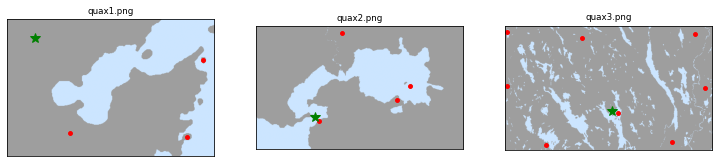

In [ ]:
def zeige_karte(achse, karte, titel):
    klein = karte['land'][::4, ::4]
    farbe = np.zeros(klein.shape + (3,))
    farbe[klein] = (0.62, 0.62, 0.62)                    # Land
    farbe[~klein] = (0.80, 0.90, 1.00)                   # Wasser
    achse.imshow(farbe, extent=(0, karte['breite'], karte['hoehe'], 0))
    for s in karte['starts']:
        achse.plot(2 * s[0] + 1, 2 * s[1] + 1, 'o', color='red', markersize=4)
    achse.plot(2 * karte['ziel'][0] + 1, 2 * karte['ziel'][1] + 1, '*', color='green', markersize=10)
    achse.set_title(titel, fontsize=9)
    achse.set_xticks([])
    achse.set_yticks([])


fig, achsen = plt.subplots(1, 3, figsize=(13, 3.2))
for nr in (1, 2, 3):
    zeige_karte(achsen[nr - 1], karten[nr], 'quax%d.png' % nr)
plt.show()

## Schritt 5: Version 1 – A* und nachsehen, wo man gerade sucht

Die einfachste Strategie: Wir lassen A* vom Start zur Stadt suchen, als ob Quax die Karte kennen würde. In der Warteschlange stehen
Tupel `(f, -g, planquadrat, vorgaenger)`: `g` ist die Zahl der Schritte vom Start, `f = g + Manhattan-Abstand zur Stadt`. Bei gleichem
`f` kommt das Planquadrat mit dem größeren `g` zuerst (darum `-g`), es liegt näher am Ziel.

Erst wenn A* ein Planquadrat aus der Warteschlange nimmt, schickt Quax den Quadcopter los (`klaere`). Ist es Wasser, wird es
verworfen. Ist es gemischt und der Vorgänger auch, entscheidet ein Grenzflug, ob der Übergang erlaubt ist; wenn nicht, bleibt das
Planquadrat offen und kann noch über einen anderen Nachbarn erreicht werden. Ist die Warteschlange leer, ohne dass die Stadt erreicht
wurde, gibt es keinen Weg. Weil A* mit dem Manhattan-Abstand einen kürzesten Weg findet, ist der Weg von Version 1 der kürzeste
mögliche in unserem Modell.

In [ ]:
def abstand(p, q):
    return abs(p[0] - q[0]) + abs(p[1] - q[1])


def version1(karte, start, ziel):
    wissen = neues_wissen()
    vorgaenger = {}                     # fertige Planquadrate (begehbar) mit ihrem Vorgänger
    wasser = set()
    schlange = [(abstand(start, ziel), 0, start, None)]
    angesehen = 0
    while schlange:
        f, minus_g, p, vor = heapq.heappop(schlange)
        if p in vorgaenger or p in wasser:
            continue
        angesehen = angesehen + 1
        wert = klaere(karte, wissen, p[0], p[1])
        if wert == 'W':
            wasser.add(p)
            continue
        if vor is not None and wert == 'G' and blatt(karte, wissen, vor[0], vor[1])[3] == 'G':
            schluessel = grenze(vor, p)
            if schluessel not in wissen['grenzen']:
                grenzflug(karte, wissen, vor, p)
            if wissen['grenzen'][schluessel] == 'W':
                continue                        # über diese Grenze nicht, vielleicht von anderswo
        vorgaenger[p] = vor
        if p == ziel:
            weg = []
            while p is not None:
                weg.append(p)
                p = vorgaenger[p]
            weg.reverse()
            return wissen, weg, angesehen
        g = -minus_g + 1
        for q in nachbarn(karte, p):
            if q not in vorgaenger and q not in wasser:
                heapq.heappush(schlange, (g + abstand(q, ziel), -g, q, p))
    return wissen, None, angesehen


def zeige_ergebnis(nr, start, wissen, weg, zaehler):
    if weg is None:
        weg_text = 'kein Weg  '
    else:
        weg_text = 'Weg %5d' % (len(weg) - 1)
        assert pruefe_weg(wahrheit[nr], weg, start, karten[nr]['ziel'])
    assert (weg is not None) == wahrheit[nr]['erreichbar'][start[1]][start[0]]
    print('quax%d  Start %-12s %s   Flüge: %6d (davon Grenzflüge %4d)  %s' %
          (nr, pixel(start), weg_text, len(wissen['liste']), len(wissen['grenzen']), zaehler))


ergebnis_v1 = {}


def alle_v1(nr):
    for start in karten[nr]['starts']:
        wissen, weg, angesehen = version1(karten[nr], start, karten[nr]['ziel'])
        ergebnis_v1[(nr, start)] = (wissen, weg)
        zeige_ergebnis(nr, start, wissen, weg, 'angesehen: %d' % angesehen)


alle_v1(1)

quax1  Start (510, 914)   Weg   525   Flüge:      9 (davon Grenzflüge    0)  angesehen: 526
quax1  Start (1454, 948)  Weg  1042   Flüge:    364 (davon Grenzflüge   27)  angesehen: 1914
quax1  Start (1582, 328)  kein Weg     Flüge:    297 (davon Grenzflüge   16)  angesehen: 512


Die Weglänge zählt die Schritte von Planquadrat zu Planquadrat (je 20 m). Jeder gefundene Weg ist vom Schiedsrichter geprüft
(`assert` in `zeige_ergebnis`), ebenso, dass „kein Weg“ stimmt. Die anderen beiden Landschaften:

In [ ]:
alle_v1(2)

quax2  Start (614, 926)   Weg  2332   Flüge:  17952 (davon Grenzflüge 1415)  angesehen: 388478
quax2  Start (844, 66)    Weg   837   Flüge:   4567 (davon Grenzflüge  225)  angesehen: 95905
quax2  Start (1384, 726)  Weg  2051   Flüge:  17455 (davon Grenzflüge  918)  angesehen: 388486
quax2  Start (1514, 582)  kein Weg     Flüge:    166 (davon Grenzflüge    7)  angesehen: 214


In [ ]:
alle_v1(3)

quax3  Start (16, 58)     Weg   876   Flüge:   5672 (davon Grenzflüge  320)  angesehen: 32046
quax3  Start (22, 566)    Weg   627   Flüge:   6141 (davon Grenzflüge  350)  angesehen: 34634
quax3  Start (390, 1124)  Weg   792   Flüge:  13328 (davon Grenzflüge  765)  angesehen: 71986
quax3  Start (726, 120)   Weg   490   Flüge:   1157 (davon Grenzflüge   61)  angesehen: 4300
quax3  Start (1070, 828)  kein Weg     Flüge:    242 (davon Grenzflüge   12)  angesehen: 280
quax3  Start (1584, 1098) Weg   646   Flüge:  13070 (davon Grenzflüge  832)  angesehen: 90380
quax3  Start (1802, 74)   Weg   823   Flüge:  18210 (davon Grenzflüge 1129)  angesehen: 150254
quax3  Start (1898, 590)  Weg   713   Flüge:  16551 (davon Grenzflüge 1041)  angesehen: 93351


**Was ist hier schlecht?** A* will den kürzesten Weg und sieht dafür jedes Planquadrat an, das noch auf einen kürzeren Weg hoffen lässt.
Liegt ein See zwischen Start und Stadt, sind das sehr viele, und jedes kostet Flüge, oft bis hinunter zu einem einzelnen
gemischten Planquadrat am Ufer. Bei sechs Starts braucht Version 1 über 10.000 Flüge. Dabei verlangt die Aufgabe gar keinen
kürzesten Weg, sondern **wenige Flüge**.

## Schritt 6: Teil (a) – Was wissen wir nach einigen Flügen?

Statt einzelner Planquadrate betrachten wir jetzt die **Blätter** des Quadtrees als Knoten eines Graphen. Zwei Blätter sind
Nachbarn, wenn sie eine gemeinsame Kante haben. `nachbar_blaetter` läuft an den vier Seiten eines Blattes entlang und springt dabei von
Blatt zu Blatt (ein großes Nachbarblatt deckt viele Planquadrate der Seite auf einmal ab).

Ein Weg durch Blätter ist für Quax gangbar, wenn jedes Blatt Land (`L`) oder ein gemischtes Planquadrat (`G`) ist und für je zwei
aufeinander folgende gemischte Planquadrate der Grenzflug nicht „Wasser“ gemeldet hat: Durch ein Landquadrat kommt er von jeder
Seite zu jeder anderen.

`suche` ist A* über die Blätter. Die Kosten setzen sich zusammen aus
- dem Abstand der Mittelpunkte der Blätter in Pixeln (also in 10 m), und
- `K` für jedes **unbekannte** Blatt und jede unbekannte Grenze zwischen zwei gemischten Planquadraten auf dem Weg (jedes davon kostet
  einen Flug).

Mit `unbekannt_erlaubt=False` darf der Weg nur durch Bekanntes führen (vorsichtig), sonst wird alles Unbekannte als begehbar
angenommen (hoffnungsvoll). `entscheide` ist das Programmmodul aus Teil (a).

In [ ]:
def nachbar_blaetter(karte, wissen, b):
    x, y, s, wert = b
    B, H = karte['B'], karte['H']
    erg = []
    if x + s < B:                                   # Osten
        t = y
        while t < min(y + s, H):
            n = blatt(karte, wissen, x + s, t)
            erg.append(n)
            t = n[1] + n[2]                         # hinter das Ende dieses Nachbarblatts springen
    if x > 0:                                       # Westen
        t = y
        while t < min(y + s, H):
            n = blatt(karte, wissen, x - 1, t)
            erg.append(n)
            t = n[1] + n[2]
    if y + s < H:                                   # Süden
        t = x
        while t < min(x + s, B):
            n = blatt(karte, wissen, t, y + s)
            erg.append(n)
            t = n[0] + n[2]
    if y > 0:                                       # Norden
        t = x
        while t < min(x + s, B):
            n = blatt(karte, wissen, t, y - 1)
            erg.append(n)
            t = n[0] + n[2]
    return erg


def mitte(b):
    """Mittelpunkt eines Blattes in Pixeln: das Blatt (x, y, s) reicht von Pixel 2x bis 2x + 2s."""
    return (2 * b[0] + b[2], 2 * b[1] + b[2])


def suche(karte, wissen, start, ziel, K, unbekannt_erlaubt=True):
    erstes = blatt(karte, wissen, start[0], start[1])
    letztes = blatt(karte, wissen, ziel[0], ziel[1])
    if not unbekannt_erlaubt and (erstes[3] == '?' or letztes[3] == '?'):
        return None, 0
    ziel_mitte = mitte(letztes)
    kosten = {erstes: 0}
    if erstes[3] == '?':
        kosten[erstes] = K
    vorgaenger = {erstes: None}
    schlange = [(kosten[erstes] + abstand(mitte(erstes), ziel_mitte), kosten[erstes], erstes)]
    besucht = 0
    while schlange:
        f, k, b = heapq.heappop(schlange)
        if k > kosten[b]:
            continue                                # veralteter Eintrag
        besucht = besucht + 1
        if b == letztes:
            weg = []
            while b is not None:
                weg.append(b)
                b = vorgaenger[b]
            weg.reverse()
            return weg, besucht
        for n in nachbar_blaetter(karte, wissen, b):
            if n[3] == 'W':
                continue
            neu = k + abstand(mitte(b), mitte(n))
            if n[3] == '?':
                if not unbekannt_erlaubt:
                    continue
                neu = neu + K
            if b[3] == 'G' and n[3] == 'G':           # zwei gemischte Planquadrate: die Grenze zählt
                g = wissen['grenzen'].get(grenze((b[0], b[1]), (n[0], n[1])))
                if g == 'W':
                    continue
                if g is None:
                    if not unbekannt_erlaubt:
                        continue
                    neu = neu + K
            if n not in kosten or neu < kosten[n]:
                kosten[n] = neu
                vorgaenger[n] = b
                heapq.heappush(schlange, (neu + abstand(mitte(n), ziel_mitte), neu, n))
    return None, besucht


def entscheide(karte, wissen, start, ziel):
    weg, besucht = suche(karte, wissen, start, ziel, 0, unbekannt_erlaubt=False)
    if weg is not None:
        return 'Es gibt einen Weg.'
    weg, besucht = suche(karte, wissen, start, ziel, 0, unbekannt_erlaubt=True)
    if weg is None:
        return 'Es gibt sicher keinen Weg.'
    return 'Mehr Flüge nötig.'

`entscheide` bekommt die Flüge als `wissen`. Damit man es mit beliebigen Flugergebnissen füttern kann, baut `wissen_aus` das Wissen
aus einer Liste von Flügen auf, wie sie in `wissen['liste']` steht. Als Beispiel nehmen wir die Flüge, die Version 1 für die
Starts `(1454, 948)` und `(1582, 328)` in `quax1.png` gemacht hat, und fragen nach den ersten 0, 10, 100 und 200 Flügen, nach allen
außer dem letzten und nach allen.

In [ ]:
def wissen_aus(fluege):
    wissen = neues_wissen()
    for schluessel, ergebnis in fluege:
        if len(schluessel) == 3:
            wissen['quadrate'][schluessel] = ergebnis
        else:
            wissen['grenzen'][schluessel] = ergebnis
        wissen['liste'].append((schluessel, ergebnis))
    return wissen


karte = karten[1]
entschieden = {}
for start in ((727, 474), (791, 164)):
    alle_fluege = ergebnis_v1[(1, start)][0]['liste']
    print('Start bei Pixel', pixel(start), '- Version 1 hat', len(alle_fluege), 'Flüge gemacht')
    for anzahl in (0, 10, 100, 200, len(alle_fluege) - 1, len(alle_fluege)):
        antwort = entscheide(karte, wissen_aus(alle_fluege[:anzahl]), start, karte['ziel'])
        print('   nach %3d Flügen: %s' % (anzahl, antwort))
        entschieden[(start, anzahl)] = antwort

Start bei Pixel (1454, 948) - Version 1 hat 364 Flüge gemacht
   nach   0 Flügen: Mehr Flüge nötig.
   nach  10 Flügen: Mehr Flüge nötig.
   nach 100 Flügen: Mehr Flüge nötig.
   nach 200 Flügen: Mehr Flüge nötig.
   nach 363 Flügen: Mehr Flüge nötig.
   nach 364 Flügen: Es gibt einen Weg.
Start bei Pixel (1582, 328) - Version 1 hat 297 Flüge gemacht
   nach   0 Flügen: Mehr Flüge nötig.
   nach  10 Flügen: Mehr Flüge nötig.
   nach 100 Flügen: Mehr Flüge nötig.
   nach 200 Flügen: Mehr Flüge nötig.
   nach 296 Flügen: Mehr Flüge nötig.
   nach 297 Flügen: Es gibt sicher keinen Weg.


In beiden Fällen bringt erst der letzte Flug die Entscheidung: Version 1 hört genau dann auf, wenn die Antwort feststeht, und
verschwendet am Ende keinen Flug. Ohne Flüge (`0`) weiß `entscheide` natürlich auch nichts.

## Schritt 7: Version 2 – hoffnungsvoll planen im Quadtree (Teil b)

**Die Strategie:**
1. Plane mit `suche` einen hoffnungsvollen Weg über die Blätter (Unbekanntes gilt als begehbar, kostet aber `K`).
2. Gibt es keinen, gibt es sicher keinen Weg: fertig.
3. Gehe den Plan vom Start aus entlang. Fliege über jedes unbekannte Blatt, und zwischen zwei gemischten Planquadraten, deren Grenze
   noch unbekannt ist, mache einen Grenzflug. Sobald ein Flug „Wasser“ meldet, ist der Plan gescheitert: zurück zu 1.
4. Ist auf dem Plan nichts mehr unbekannt, ist er ein sicherer Weg: fertig.

Meldet ein großes unbekanntes Blatt „Gemischt“, wird es zu vier unbekannten Vierteln; der Plan wird dann in der nächsten Runde genauer.
Wir wählen `K = 100`: Ein Flug ist so viel wert wie ein Umweg von 100 Pixeln, also 1 km. So meidet die Suche Gegenden, in denen
viel Kleinkram liegt, und nimmt lieber einen Umweg durch große Landflächen.

Der Plan ist eine Kette von Blättern. `zellweg` macht daraus einen Weg aus Planquadraten: eine Breitensuche, die nur die Planquadrate
dieser Blätter benutzt und nur bekannte Grenzen zwischen gemischten Planquadraten überquert.

In [ ]:
K = 100


def version2(karte, start, ziel, K):
    wissen = neues_wissen()
    runden = 0
    while True:
        runden = runden + 1
        plan, besucht = suche(karte, wissen, start, ziel, K)
        if plan is None:
            return wissen, None, runden
        alles_bekannt = True
        for i in range(len(plan)):
            x, y, s, wert = plan[i]
            if wert == '?':
                alles_bekannt = False
                if fliege(karte, wissen, x, y, s) == 'W':
                    break                                       # Plan gescheitert
            elif wert == 'G' and i > 0 and plan[i - 1][3] == 'G':
                a = (plan[i - 1][0], plan[i - 1][1])
                if grenze(a, (x, y)) not in wissen['grenzen']:
                    alles_bekannt = False
                    if grenzflug(karte, wissen, a, (x, y)) == 'W':
                        break
        if alles_bekannt:
            return wissen, plan, runden


def zellweg(karte, wissen, plan, start, ziel):
    wert = {}
    for x, y, s, w in plan:
        for py in range(y, min(y + s, karte['H'])):
            for px in range(x, min(x + s, karte['B'])):
                wert[(px, py)] = w
    vorgaenger = {start: None}
    schlange = deque([start])
    while schlange:
        p = schlange.popleft()
        if p == ziel:
            break
        for q in nachbarn(karte, p):
            if q in wert and q not in vorgaenger:
                if wert[p] == 'G' and wert[q] == 'G' and wissen['grenzen'].get(grenze(p, q)) not in ('L', 'G'):
                    continue
                vorgaenger[q] = p
                schlange.append(q)
    weg = []
    p = ziel
    while p is not None:
        weg.append(p)
        p = vorgaenger[p]
    weg.reverse()
    return weg


ergebnis_v2 = {}


def alle_v2(nr):
    for start in karten[nr]['starts']:
        wissen, plan, runden = version2(karten[nr], start, karten[nr]['ziel'], K)
        weg = None
        if plan is not None:
            weg = zellweg(karten[nr], wissen, plan, start, karten[nr]['ziel'])
        ergebnis_v2[(nr, start)] = (wissen, weg, plan)
        zeige_ergebnis(nr, start, wissen, weg, 'Runden: %d' % runden)


alle_v2(1)
alle_v2(2)
alle_v2(3)

quax1  Start (510, 914)   Weg   525   Flüge:      9 (davon Grenzflüge    0)  Runden: 5
quax1  Start (1454, 948)  Weg  1050   Flüge:    116 (davon Grenzflüge    0)  Runden: 21
quax1  Start (1582, 328)  kein Weg     Flüge:    121 (davon Grenzflüge    0)  Runden: 28
quax2  Start (614, 926)   Weg  2434   Flüge:    516 (davon Grenzflüge    0)  Runden: 105
quax2  Start (844, 66)    Weg   871   Flüge:    363 (davon Grenzflüge    0)  Runden: 66
quax2  Start (1384, 726)  Weg  2191   Flüge:    731 (davon Grenzflüge   14)  Runden: 151
quax2  Start (1514, 582)  kein Weg     Flüge:     57 (davon Grenzflüge    0)  Runden: 18
quax3  Start (16, 58)     Weg   904   Flüge:    281 (davon Grenzflüge    0)  Runden: 28
quax3  Start (22, 566)    Weg   659   Flüge:    309 (davon Grenzflüge    3)  Runden: 49
quax3  Start (390, 1124)  Weg   934   Flüge:    907 (davon Grenzflüge    1)  Runden: 185
quax3  Start (726, 120)   Weg   490   Flüge:    100 (davon Grenzflüge    0)  Runden: 16
quax3  Start (1070, 828)  ke

Statt vieler Tausend Flüge braucht Version 2 nur noch einige Hundert. Die Wege sind etwas länger als die kürzesten aus Version 1, aber
alle vom Schiedsrichter bestätigt.

## Schritt 8: Vergleich mit den Lösungshinweisen

Tabelle 3 der Lösungshinweise nennt für jeden Start die Zahl der Flüge und die Weglänge (in Planquadraten von 20 m). Die Hinweise
planen mit A* über die Planquadrate und klären dann der Reihe nach die Planquadrate auf dem geplanten Weg im Quadtree (wie unser
`klaere`). Der Startpunkt `(844, 66)` steht dort viermal, wir nehmen ihn einmal.

In [ ]:
HINWEISE = {(1, (510, 914)): (9, 524), (1, (1454, 948)): (1850, 1177), (1, (1582, 328)): (281, 0),
            (2, (614, 926)): (13057, 2404), (2, (844, 66)): (1183, 866), (2, (1384, 726)): (12541, 2578),
            (2, (1514, 582)): (159, 0),
            (3, (16, 58)): (2091, 1051), (3, (22, 566)): (9392, 892), (3, (390, 1124)): (10266, 1309),
            (3, (726, 120)): (390, 525), (3, (1070, 828)): (230, 0), (3, (1584, 1098)): (1640, 665),
            (3, (1802, 74)): (2212, 1078), (3, (1898, 590)): (1952, 834)}


def laenge(weg):
    if weg is None:
        return 0
    return len(weg) - 1


print('                           Flüge                    Weglänge')
print('Beispiel Start          Hinweise    V1     V2    Hinweise   V1    V2')
summe = [0, 0, 0]
for nr in (1, 2, 3):
    for start in karten[nr]['starts']:
        h_fluege, h_laenge = HINWEISE[(nr, pixel(start))]
        w1, weg1 = ergebnis_v1[(nr, start)]
        w2, weg2, plan2 = ergebnis_v2[(nr, start)]
        print('quax%d    %-13s %8d %6d %6d    %6d %6d %5d' % (nr, pixel(start), h_fluege, len(w1['liste']), len(w2['liste']),
                                                         h_laenge, laenge(weg1), laenge(weg2)))
        summe[0] = summe[0] + h_fluege
        summe[1] = summe[1] + len(w1['liste'])
        summe[2] = summe[2] + len(w2['liste'])
print('Summe                  %8d %6d %6d' % (summe[0], summe[1], summe[2]))

                           Flüge                    Weglänge
Beispiel Start          Hinweise    V1     V2    Hinweise   V1    V2
quax1    (510, 914)           9      9      9       524    525   525
quax1    (1454, 948)       1850    364    116      1177   1042  1050
quax1    (1582, 328)        281    297    121         0      0     0
quax2    (614, 926)       13057  17952    516      2404   2332  2434
quax2    (844, 66)         1183   4567    363       866    837   871
quax2    (1384, 726)      12541  17455    731      2578   2051  2191
quax2    (1514, 582)        159    166     57         0      0     0
quax3    (16, 58)          2091   5672    281      1051    876   904
quax3    (22, 566)         9392   6141    309       892    627   659
quax3    (390, 1124)      10266  13328    907      1309    792   934
quax3    (726, 120)         390   1157    100       525    490   490
quax3    (1070, 828)        230    242    161         0      0     0
quax3    (1584, 1098)      1640  13070    

**Ehrlicher Vergleich:**

- Bei den drei Starts ohne Weg sind wir uns mit den Hinweisen einig.
- Version 1 braucht insgesamt etwa doppelt so viele Flüge wie die Hinweise, findet aber in unserem Modell immer einen kürzesten Weg. Die
  Wege der Hinweise sind meist länger; ihre Wegsuche ist also wohl nicht genau unser A*.
- Version 2 braucht bei 14 der 15 Starts weniger Flüge als die Hinweise, insgesamt nur etwa 9 Prozent davon. Beim Start
  `(510, 914)` in `quax1.png` sind es wie bei Version 1 und den Hinweisen 9 Flüge; dort führt der kürzeste Weg durch große Landflächen.
- Die Wege von Version 2 sind bis auf drei Ausnahmen kürzer als die der Hinweise: Bei `(510, 914)` zählen die Hinweise einen Schritt
  weniger (vielleicht zählen sie anders), in `quax2.png` ist unser Weg bei `(614, 926)` länger (2434 statt 2404) und bei `(844, 66)`
  auch (871 statt 866). Wir sparen Flüge und nehmen dafür manchmal einen kleinen Umweg in Kauf.
- Ganz gerecht ist der Vergleich nicht: Wir wissen nicht genau, wie die Hinweise mit dem Sonderfall umgehen und ob sie Quadrate
  außerhalb des Bildes befliegen. Unsere Zahlen enthalten die Grenzflüge.

## Schritt 9: Teil (c) – die Darstellung

`zeichne` trägt in die Karte alle Testgebiete ein: Land-Quadrate grün, Wasser-Quadrate blau, gemischte Planquadrate orange gefüllt,
gemischte größere Quadrate nur als dünner oranger Rahmen. Der Weg ist rot. Für jeden Start gibt es ein eigenes Bild.

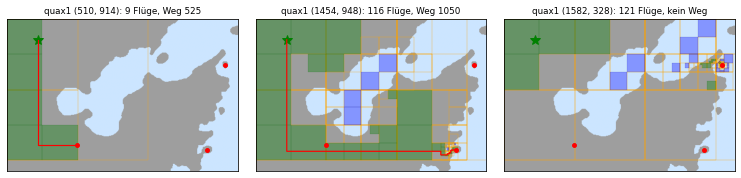

In [ ]:
def zeichne(achse, karte, wissen, weg, titel):
    zeige_karte(achse, karte, titel)
    for (x, y, s), wert in wissen['quadrate'].items():
        if wert == 'L':
            achse.add_patch(Rectangle((2 * x, 2 * y), 2 * s, 2 * s, facecolor='green', alpha=0.35, edgecolor='darkgreen', linewidth=0.3))
        elif wert == 'W':
            achse.add_patch(Rectangle((2 * x, 2 * y), 2 * s, 2 * s, facecolor='blue', alpha=0.35, edgecolor='navy', linewidth=0.3))
        elif s == 1:
            achse.add_patch(Rectangle((2 * x, 2 * y), 2, 2, facecolor='orange', edgecolor='orange', linewidth=0.5))
        else:
            achse.add_patch(Rectangle((2 * x, 2 * y), 2 * s, 2 * s, fill=False, edgecolor='orange', linewidth=0.3))
    if weg is not None:
        achse.plot([2 * p[0] + 1 for p in weg], [2 * p[1] + 1 for p in weg], color='red', linewidth=1.2)
    achse.set_xlim(0, karte['breite'])
    achse.set_ylim(karte['hoehe'], 0)


def zeichne_alle(nr, spalten):
    starts = karten[nr]['starts']
    zeilen = (len(starts) + spalten - 1) // spalten
    fig, achsen = plt.subplots(zeilen, spalten, figsize=(3.6 * spalten, 2.5 * zeilen), squeeze=False)
    for i in range(zeilen * spalten):
        achse = achsen[i // spalten][i % spalten]
        if i >= len(starts):
            achse.axis('off')
            continue
        wissen, weg, plan = ergebnis_v2[(nr, starts[i])]
        if weg is None:
            text = 'kein Weg'
        else:
            text = 'Weg %d' % laenge(weg)
        zeichne(achse, karten[nr], wissen, weg, 'quax%d %s: %d Flüge, %s' % (nr, pixel(starts[i]), len(wissen['liste']), text))
    plt.tight_layout()
    plt.show()


zeichne_alle(1, 3)

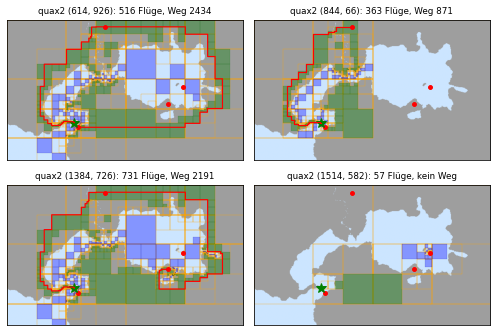

In [ ]:
zeichne_alle(2, 2)

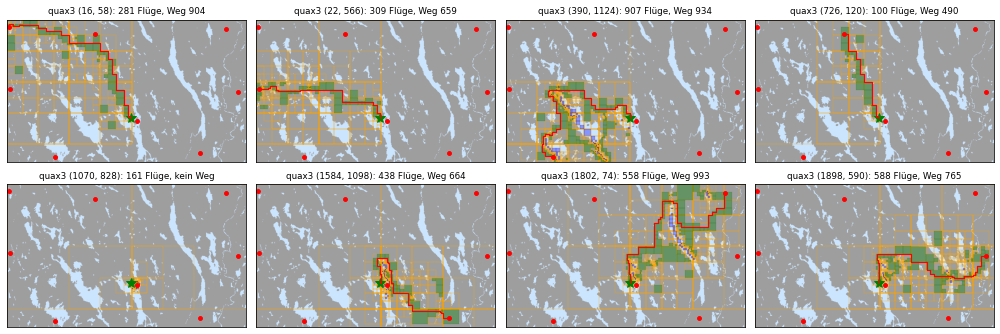

In [ ]:
zeichne_alle(3, 4)

Man sieht, wie die Strategie arbeitet: Große grüne Quadrate bestätigen mit einem Flug weite Landflächen, große blaue Quadrate schließen
Seen aus. Fein aufgelöst (kleine Quadrate, orange Planquadrate) wird nur an den Ufern, an denen der Plan entlangläuft, und an Flüssen,
die Quax durchschwimmen kann. Zum Vergleich Version 1 beim Start `(1454, 948)` in `quax1.png`, links, und Version 2, rechts:

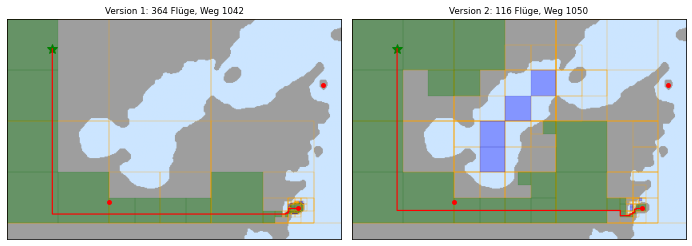

In [ ]:
fig, achsen = plt.subplots(1, 2, figsize=(10, 3.5))
start = (727, 474)
for i, (name, ergebnis) in enumerate((('Version 1', ergebnis_v1), ('Version 2', ergebnis_v2))):
    wissen, weg = ergebnis[(1, start)][0], ergebnis[(1, start)][1]
    zeichne(achsen[i], karten[1], wissen, weg, '%s: %d Flüge, Weg %d' % (name, len(wissen['liste']), laenge(weg)))
plt.tight_layout()
plt.show()

## Schritt 10: Teil (d) – Landschaften mit sehr vielen Flügen

Ja, die gibt es. Der Quadtree spart nur dann Flüge, wenn es große Flächen gibt, die ganz Land oder ganz Wasser sind. Zwei eigene
Landschaften zeigen das Problem:

1. **Sprenkel (256 × 256 Pixel):** Überall Land, aber in jedem Planquadrat ist das linke obere Pixel ein kleiner Tümpel. Jedes Quadrat des Quadtrees ist
   dann gemischt, auch jedes einzelne Planquadrat. Quax kann überall gehen, aber kein Flug außer über ein einzelnes Planquadrat sagt
   etwas Brauchbares. Dazu kommt für jeden Schritt ein Grenzflug, weil immer zwei gemischte Planquadrate aneinanderstoßen.
2. **Schlangenlinie (128 × 128 Pixel):** Wasser mit einem Landstreifen von 20 m Breite, der in Schlangenlinien hin und her läuft. Jede Runde plant
   hoffnungsvoll quer durch das Unbekannte und muss dann eine weitere Wasserrinne entdecken.

`kunst_karte` baut aus einer numpy-Tabelle eine `karte` wie `lies`.

Sprenkel        Weg  254, Flüge:  3904 (davon Grenzflüge  290), Runden: 76
Schlangenlinie  Weg 1036, Flüge:  2562 (davon Grenzflüge    0), Runden: 667


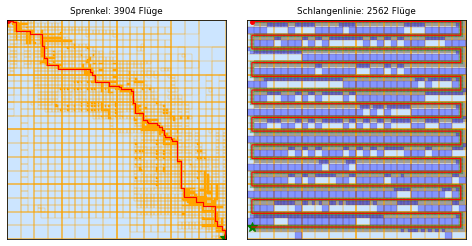

In [ ]:
def kunst_karte(land, start, ziel):
    hoehe, breite = land.shape
    B, H = (breite + 1) // 2, (hoehe + 1) // 2
    N = 1
    while N < max(B, H):
        N = 2 * N
    return {'land': land, 'breite': breite, 'hoehe': hoehe, 'B': B, 'H': H, 'N': N, 'starts': [start], 'ziel': ziel}


sprenkel = np.ones((256, 256), dtype=bool)
sprenkel[0::2, 0::2] = False                    # linkes oberes Pixel jedes Planquadrats ist Wasser

schlange_land = np.zeros((128, 128), dtype=bool)
for reihe in range(0, 16):                       # 16 waagerechte Streifen, je 2 Pixel hoch, im Abstand von 8 Pixeln
    schlange_land[8 * reihe:8 * reihe + 2, 2:126] = True
    if reihe < 15:                               # Verbindung abwechselnd rechts und links
        if reihe % 2 == 0:
            schlange_land[8 * reihe:8 * reihe + 10, 124:126] = True
        else:
            schlange_land[8 * reihe:8 * reihe + 10, 2:4] = True

kunst = {'Sprenkel': kunst_karte(sprenkel, (0, 0), (127, 127)),
         'Schlangenlinie': kunst_karte(schlange_land, (1, 0), (1, 60))}
for name in kunst:
    karte = kunst[name]
    wahr = schiedsrichter(karte)
    start, ziel = karte['starts'][0], karte['ziel']
    wissen, plan, runden = version2(karte, start, ziel, K)
    weg = zellweg(karte, wissen, plan, start, ziel)
    assert pruefe_weg(wahr, weg, start, ziel)
    print('%-15s Weg %4d, Flüge: %5d (davon Grenzflüge %4d), Runden: %d' %
          (name, laenge(weg), len(wissen['liste']), len(wissen['grenzen']), runden))
    kunst[name]['ergebnis'] = (wissen, weg)

fig, achsen = plt.subplots(1, 2, figsize=(7, 3.5))
for i, name in enumerate(kunst):
    wissen, weg = kunst[name]['ergebnis']
    zeichne(achsen[i], kunst[name], wissen, weg, '%s: %d Flüge' % (name, len(wissen['liste'])))
plt.tight_layout()
plt.show()

Bei den Sprenkeln ist der Weg von Ecke zu Ecke 254 Schritte lang, und Version 2 braucht dafür 3.904 Flüge, mehr als 15 pro
Schritt. Selbst wer die Karte kennt, kommt nicht mit wenigen Flügen aus: Ein Flug über ein Quadrat, das größer als ein Planquadrat ist,
meldet hier immer „Gemischt“ und hilft nicht weiter. Jedes der 255 Planquadrate des Weges muss also einzeln beflogen werden, und jede
der 254 Grenzen dazwischen auch, das sind mindestens 509 Flüge. Unsere Strategie braucht noch viel mehr, weil sie hoffnungsvoll durch
große unbekannte Quadrate plant, die sich dann Stufe für Stufe als gemischt herausstellen.

Bei der Schlangenlinie ist der Weg 1.036 Schritte lang; Version 2 braucht 2.562 Flüge. Der Landstreifen ist nur ein
Planquadrat breit, jedes Planquadrat des Weges muss also einzeln bestätigt werden. Dazu kommen sehr viele Runden: Die hoffnungsvolle
Planung führt immer wieder quer durch das Unbekannte und muss jede Wasserrinne erst entdecken.

**Allgemein:** Viele Flüge braucht es, wenn
- das Wasser fein verteilt ist (viele kleine Tümpel, Sprenkel, Schachbrett), sodass große Quadrate fast immer „Gemischt“ melden,
- der Weg lang und schmal ist (enge Landbrücken, Labyrinthe, Schlangenlinien), sodass er Planquadrat für Planquadrat geklärt werden
  muss,
- die hoffnungsvolle Planung immer wieder in Sackgassen läuft (viele Buchten oder Seen mit nur einem Durchgang).

Wenige Flüge reichen dagegen bei großen zusammenhängenden Land- und Wasserflächen, wie in den Beispielen der BWINF-Website.

## Für Neugierige

**Warum ist „sicher kein Weg“ wirklich sicher?** Die hoffnungsvolle Suche nimmt alles Unbekannte als begehbar an. Jeder echte Weg ist
also auch für sie ein Weg, denn er führt nur durch Planquadrate, die nicht Wasser sind, und über erlaubte Grenzen. Findet sie keinen,
kann es keinen echten geben. Umgekehrt benutzt die vorsichtige Suche nur Bestätigtes; ihr Weg ist echt.

**Warum wird Version 2 fertig?** In jeder Runde, in der der Plan noch Unbekanntes enthält, macht sie mindestens einen neuen Flug. Es
gibt aber nur endlich viele Quadrate im Quadtree und endlich viele Grenzen.

**Wie viel macht `K` aus?** Beim Erstellen dieses Notebooks haben wir Version 2 mit anderen Werten für `K` laufen lassen (Summe der
Flüge über alle 15 Starts):

| `K` | Flüge (Summe) | Weglängen (Summe) |
|-----|---------------|-------------------|
| 0 | 18.097 | 11.836 |
| 10 | 8.489 | 11.950 |
| 30 | 6.444 | 12.080 |
| 100 | 5.255 | 12.480 |
| 1000 | 4.463 | 12.978 |
| Version 1 | 115.181 | 11.754 |
| Lösungshinweise | 57.253 | 13.903 |

Schon mit `K = 0` (nur der Abstand zählt) spart die Planung über die Blätter gegenüber Version 1 und den Hinweisen viel: Ein Weg
durch ein großes unbekanntes Quadrat ist ein Schritt, und beflogen wird nur dieses eine Quadrat statt vieler Planquadrate. Mit
größerem `K` werden es noch weniger Flüge, die Wege werden aber länger. Mit kleinem `K` braucht die Rechnung außerdem deutlich
länger; darum rechnen wir die Tabelle hier nicht vor.

**Und MiniZinc?** Diesmal nicht. Die Aufgabe ist ein **Erkundungsproblem**: Was der nächste Flug bringt, erfährt Quax erst, wenn der
Quadcopter zurück ist, und die Strategie muss sich danach richten. Ein Modell für MiniZinc braucht dagegen alle Daten vorher. Man könnte
höchstens mit dem Wissen des Schiedsrichters fragen, wie viele Flüge **mindestens** nötig sind, um einen Weg zu beweisen. Dafür
müsste das Modell aber über die rund 500.000 Planquadrate einer Landschaft und alle Quadrate des Quadtrees entscheiden; das ist für
einen Solver viel zu groß, und es sagt nichts über eine Strategie, die die Karte nicht kennt.

**Ideen zum Weitermachen:** Auch Quadrate, die nicht im Quadtree liegen (beliebige Lage und Größe), befliegen; vor einem Flug schätzen,
wie wahrscheinlich „Gemischt“ herauskommt (große Quadrate sind fast immer gemischt, da lohnt sich der Flug kaum); von der Stadt und vom
Start gleichzeitig suchen.